# Lab 4-04：圖檢索 vs 向量檢索——同一組題目比一比

**目標**：用 12 題（4 題單跳、8 題多跳）同時考向量 RAG 和圖檢索，分開量「檢索有沒有撈到答案」和「最後答得對不對」，
畫成長條圖，然後討論什麼時候該用哪一個。

**你會學到**
- 評估要把「檢索」和「生成」拆開量，才知道錯在哪一段
- 向量檢索在多跳題上輸在哪裡
- 圖檢索的盲點：schema 沒涵蓋的事，它一個字都答不出來

**前置**：Lab 4-01、4-02（會 import 同資料夾的 `graph_retrieval.py`）；Ollama 有 `qwen2.5:3b` 與 `bge-m3`。跑完約 3～5 分鐘。不需要 Neo4j。

**對應投影片**：「向量 RAG 答不了的兩種題」「GraphRAG 兩派分清」「GraphRAG 四種查詢模式」「選型：圖資料庫與 GraphRAG」「模組四 面試題」

![向量檢索與圖檢索的比較流程](images/graph_vs_vector.jpg)

*圖：同一個問題走兩條路。上排是向量檢索（撈最像的 3 段原文），下排朱紅色是圖檢索（找實體、走多跳子圖）；兩邊都交給同一個 LLM、同一個 prompt，最後比正確率。*

## Step 1：題目

每題附上「答案關鍵字」：回答裡出現關鍵字就算對。這種評分很粗，但對短答案夠用，而且完全不用花 LLM 呼叫。

In [1]:
import json
from pathlib import Path

questions = json.loads(Path("data/questions.json").read_text(encoding="utf-8"))
for q in questions:
    print(f"{q['id']}  [{q['type']:6}] {q['question']}  → {q['answer_keywords']}")

q01  [single] 索隆的夢想是什麼？  → ['大劍豪']
q02  [single] 喬巴吃了什麼果實？  → ['人人果實']
q03  [single] 羅賓出身哪裡？  → ['歐哈拉']
q04  [single] 娜美在船上負責什麼工作？  → ['航海士']
q05  [multi ] 和索隆同一個海賊團的船長，夢想是什麼？  → ['海賊王']
q06  [multi ] 騙人布的父親是哪個海賊團的成員？  → ['紅髮海賊團']
q07  [multi ] 騙人布的父親所在海賊團的船長是誰？  → ['香克斯']
q08  [multi ] 魯夫的結拜哥哥是哪個海賊團的人？  → ['白鬍子海賊團']
q09  [multi ] 魯夫的結拜哥哥所屬海賊團的船長吃了什麼果實？  → ['震震果實']
q10  [multi ] 打倒阿龍的人，夢想是什麼？  → ['海賊王']
q11  [multi ] 巴托洛米奧所屬大船團的帶頭人，出身哪個村子？  → ['風車村']
q12  [multi ] 擁有和道一文字的草帽海賊團成員，夢想是什麼？  → ['大劍豪']


多跳題刻意設計成：答案需要的事實分散在兩三段裡，而且**最後那一段不會提到問題裡的人名**。
例如 q07「騙人布的父親所在海賊團的船長」，香克斯是船長這件事，寫在一段完全沒提到騙人布的文字裡。

## Step 2：向量 RAG（手寫版）

跟模組 3 一樣：每段摘要算一個 bge-m3 向量，問題也算一個，用 numpy 算 cosine，取前 3 段。

In [2]:
import re

import numpy as np

from course_utils.llm import chat, embed

text = Path("data/one_piece_summaries.md").read_text(encoding="utf-8")
paragraphs = []
for block in re.split(r"^## ", text, flags=re.M)[1:]:
    head, _, body = block.partition("\n")
    paragraphs.append({"id": head.split()[0], "title": head.split(maxsplit=1)[1], "text": body.strip()})

P = np.array(embed([p["text"] for p in paragraphs]))
P /= np.linalg.norm(P, axis=1, keepdims=True)


def vector_search(question: str, k: int = 3) -> list[dict]:
    q = np.array(embed([question])[0])
    q /= np.linalg.norm(q)
    scores = P @ q
    return [{**paragraphs[i], "score": float(scores[i])} for i in np.argsort(-scores)[:k]]


def vector_context(question: str) -> str:
    return "\n\n".join(p["text"] for p in vector_search(question))


for hit in vector_search("騙人布的父親所在海賊團的船長是誰？"):
    print(f"{hit['score']:.3f}  [{hit['id']}] {hit['title']}")

0.740  [10] 說謊的狙擊手
0.534  [11] 紅髮海賊團的槍手
0.496  [03] 出海


撈到了騙人布那段和耶穌布那段，第三段是……看你的輸出。
香克斯是紅髮海賊團船長的那段（02「紅髮與草帽」）通常不在前 3：它講的是斷臂和草帽，跟「騙人布、父親」不像。

## Step 3：圖檢索

直接用上一本寫好的函式：找實體 → 剪枝 BFS 走 4 步 → 念成句子。

In [3]:
from graph_retrieval import graph_context, link_entities, load_graph

G = load_graph()
q = "騙人布的父親所在海賊團的船長是誰？"
print("起點：", link_entities(G, q))
print(graph_context(G, q))

起點： ['騙人布']
騙人布 出身 西羅布村
騙人布 是 草帽海賊團 的成員
騙人布 的夢想是 勇敢的海上戰士
騙人布 的父親是 耶穌布
魯夫 是 草帽海賊團 的船長（帶頭的人）
耶穌布 是 紅髮海賊團 的成員
魯夫 出身 風車村
魯夫 擁有 橡膠果實
魯夫 擁有 草帽
魯夫 的夢想是 海賊王
魯夫 打倒了 阿龍
魯夫 是 草帽大船團 的船長（帶頭的人）
艾斯 是 魯夫 的結拜哥哥
香克斯 是 紅髮海賊團 的船長（帶頭的人）
香克斯 擁有 草帽
阿龍 是 阿龍海賊團 的船長（帶頭的人）
艾斯 擁有 燒燒果實
艾斯 是 白鬍子海賊團 的成員


## Step 4：先只比檢索——答案有沒有在上下文裡？

生成之前先問一個更基本的問題：**給 LLM 的資料裡，到底有沒有答案？**
沒有的話，LLM 再聰明也答不對（或只能靠瞎猜）。這一步完全不用呼叫 LLM。

In [4]:
def contains_answer(context: str, q: dict) -> bool:
    return any(kw in context for kw in q["answer_keywords"])


rows = []
for q in questions:
    v_ctx, g_ctx = vector_context(q["question"]), graph_context(G, q["question"])
    rows.append({"id": q["id"], "type": q["type"], "question": q["question"],
                 "v_ctx": v_ctx, "g_ctx": g_ctx,
                 "v_hit": contains_answer(v_ctx, q), "g_hit": contains_answer(g_ctx, q)})

print("題號   類型    向量  圖")
for r in rows:
    print(f"{r['id']}   {r['type']:6}  {'O' if r['v_hit'] else 'X'}     {'O' if r['g_hit'] else 'X'}")

題號   類型    向量  圖
q01   single  O     O
q02   single  O     O
q03   single  O     O
q04   single  O     X
q05   multi   O     O
q06   multi   O     O
q07   multi   X     O
q08   multi   X     O
q09   multi   X     O
q10   multi   X     O
q11   multi   X     O
q12   multi   O     O


注意兩件事：

- 向量檢索的 X 幾乎都在多跳題：鏈條的後半段不像問題，排不進前 3。
- 圖檢索的 X 在 q04「娜美在船上負責什麼工作」：我們的 schema 根本沒有「職位」這種關係，抽三元組時就丟掉了。
  **圖只知道你設計它知道的事。**

## Step 5：端到端——讓 LLM 回答

兩邊用同一個 prompt、同一個模型，只差上下文。

In [5]:
ANSWER_SYSTEM = "只根據提供的資料回答，用一句話。資料沒有就說「資料不足」。"


def answer(context: str, question: str) -> str:
    return chat([
        {"role": "system", "content": ANSWER_SYSTEM},
        {"role": "user", "content": f"資料：\n{context}\n\n問題：{question}"},
    ])


for r, q in zip(rows, questions):
    r["v_ans"] = answer(r["v_ctx"], q["question"])
    r["g_ans"] = answer(r["g_ctx"], q["question"])
    r["v_ok"] = contains_answer(r["v_ans"], q)
    r["g_ok"] = contains_answer(r["g_ans"], q)
    print(f"{r['id']} {q['question']}")
    print(f"   向量 {'O' if r['v_ok'] else 'X'}：{r['v_ans'][:60]}")
    print(f"   圖   {'O' if r['g_ok'] else 'X'}：{r['g_ans'][:60]}")

q01 索隆的夢想是什麼？
   向量 O：索隆的夢想是成為世界第一大劍豪。
   圖   O：索隆的夢想是世界第一大劍豪。
q02 喬巴吃了什麼果實？
   向量 O：喬巴吃了人人果實。
   圖   O：喬巴吃了人人果實。
q03 羅賓出身哪裡？
   向量 O：羅賓出身歐哈拉。
   圖   O：羅賓出身於歐哈拉。
q04 娜美在船上負責什麼工作？
   向量 O：娜美在船上负责航海士的工作，也就是看天氣和畫海圖。
   圖   X：資料不足。
q05 和索隆同一個海賊團的船長，夢想是什麼？
   向量 O：羅羅亞·索隆的船長，蒙其·D·魯夫的梦想是成為海賊王。
   圖   O：魯夫，他的夢想是海賊王。因此，和索隆同一個海賈團的船長，夢想是海賊王。
q06 騙人布的父親是哪個海賊團的成員？
   向量 O：騙人布的父親耶穌布是紅髮海賊團的成員。
   圖   O：騙人布的父親耶穌布是紅髮海賊團的成員。
q07 騙人布的父親所在海賊團的船長是誰？
   向量 X：資料不足。根據提供的資料，無法確定騙人布的父親所在海賊團的船長是誰。
   圖   O：騙人布的父親耶穌布是紅髮海賊團的船長香克斯。
q08 魯夫的結拜哥哥是哪個海賊團的人？
   向量 X：艾斯不是魯夫小時候的結拜哥哥，這份信息中沒有提到艾斯與魯夫有結拜關係，且艾斯是草帽海賊團的成員。
   圖   O：魯夫的結拜哥哥艾斯是白鬍子海賊團的人。
q09 魯夫的結拜哥哥所屬海賊團的船長吃了什麼果實？
   向量 X：巴托洛米奧吃了能造出透明屏障的果實。
   圖   O：艾斯所屬的白鬍子海賊團的船長白鬍子吃了震震果實。
q10 打倒阿龍的人，夢想是什麼？
   向量 X：打倒阿龍的人，她的夢想是讀懂歷史本文，找出被抹去的那一百年。因此，答案是羅賓。
   圖   O：打倒阿龍的人，夢想是海賊王。根據提供的資料，這個人是魯夫。
q11 巴托洛米奧所屬大船團的帶頭人，出身哪個村子？
   向量 X：資料不足。题目中没有提到巴托洛米奧所屬大船團的帶頭人，所以无法确定他的出身村子。
   圖   X：資料不足。
q12 擁有和道一文字的草帽海賊團成員，夢想是什麼？
   向量 O：索隆是草帽海賊團的成員，他的夢想是成為世界第一大劍豪。
   圖   O：索隆，擁有和道一文字的草帽海賊團成員，夢想是世界第一大劍豪

## Step 6：畫出來

四組數字：向量／圖 × 檢索命中／回答正確，再分單跳、多跳。

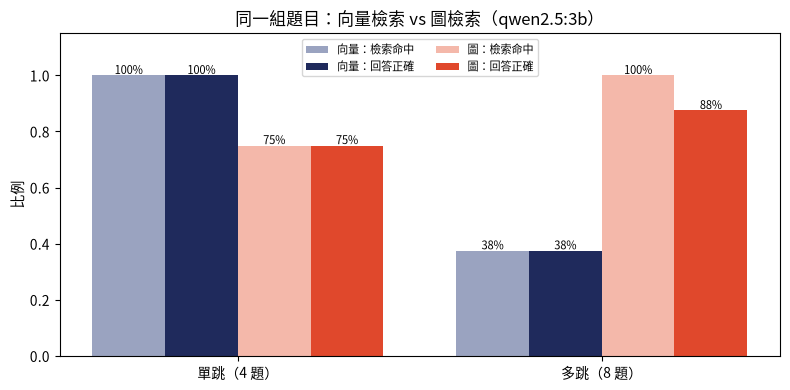

In [6]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()


def rate(key: str, kind: str) -> float:
    sel = [r for r in rows if r["type"] == kind]
    return sum(r[key] for r in sel) / len(sel)


groups = ["單跳（4 題）", "多跳（8 題）"]
series = {
    "向量：檢索命中": ("v_hit", "#9aa3c0"),
    "向量：回答正確": ("v_ok", "#1f2a5c"),
    "圖：檢索命中": ("g_hit", "#f4b8aa"),
    "圖：回答正確": ("g_ok", "#e0482c"),
}
x = np.arange(len(groups))
fig, ax = plt.subplots(figsize=(8, 4))
for i, (name, (key, color)) in enumerate(series.items()):
    vals = [rate(key, "single"), rate(key, "multi")]
    bars = ax.bar(x + (i - 1.5) * 0.2, vals, width=0.2, label=name, color=color)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=8)
ax.set_xticks(x, groups)
ax.set_ylim(0, 1.15)
ax.set_ylabel("比例")
ax.set_title("同一組題目：向量檢索 vs 圖檢索（qwen2.5:3b）")
ax.legend(fontsize=8, ncol=2, loc="upper center")
plt.tight_layout()
plt.show()

再把每一題攤開，看錯在哪一格：

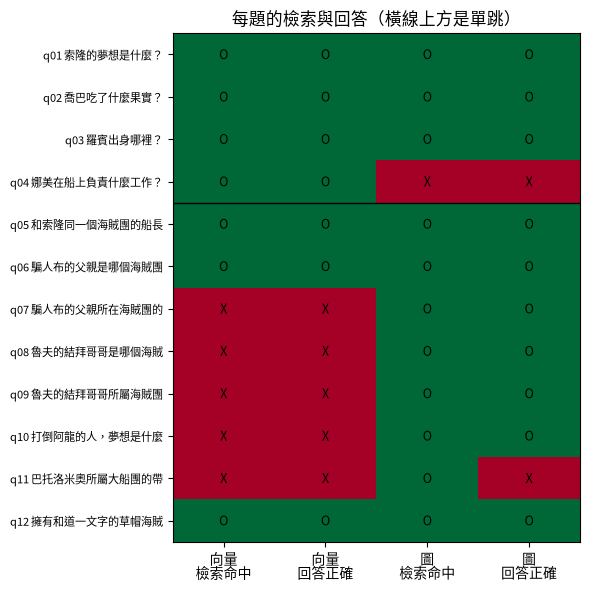

In [7]:
cols = ["v_hit", "v_ok", "g_hit", "g_ok"]
M = np.array([[r[c] for c in cols] for r in rows], dtype=float)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(4), ["向量\n檢索命中", "向量\n回答正確", "圖\n檢索命中", "圖\n回答正確"])
ax.set_yticks(range(len(rows)), [f"{r['id']} {r['question'][:12]}" for r in rows], fontsize=8)
for i in range(len(rows)):
    for j in range(4):
        ax.text(j, i, "O" if M[i, j] else "X", ha="center", va="center", fontsize=9)
ax.axhline(3.5, color="black", lw=1)
ax.set_title("每題的檢索與回答（橫線上方是單跳）")
plt.tight_layout()
plt.show()

讀這張圖的方法：

- **檢索 X、回答 X**：撈錯資料，怪檢索。
- **檢索 O、回答 X**：資料給了，模型沒串起來，怪生成（換大模型、改 prompt）。
- **檢索 X、回答 O**：要小心，模型可能是靠自己的知識猜中的，不是靠你的資料。

這就是評估要拆兩段量的原因：只看最後的正確率，你不知道該修哪裡。模組 8 會把這套做法變成固定的回歸評估。

## Step 7：什麼時候用哪一個？

把這一本看到的現象整理起來：

| 問題長什麼樣 | 建議 | 原因 |
|---|---|---|
| 答案寫在某一段裡，問法跟原文像（「索隆的夢想」） | 向量 | 便宜、不用建圖，單跳表現已經很好 |
| 要串好幾個實體（「A 的 B 的 C」） | 圖 | 沿著邊走，中間的段落不必「長得像問題」 |
| 問的是 schema 沒有的細節（職位、外號、場景描述） | 向量 | 圖只存你定義過的關係，其他資訊在抽取時就丟了 |
| 要看全貌（「故事裡有哪幾股勢力」） | GraphRAG Global Search | 兩者都撈不到；要先分群、寫社群報告再彙總（投影片「Global Search 社群報告」） |
| 資料常改、沒人維護 schema | 向量 | 建圖要抽取、正規化、人工校對，維護成本高 |

實務上最常見的是**兩個一起用**：圖負責找到「相關的是誰」，再把這些實體出現的原文段落一起撈出來，
投影片「Local Search」就是這個組合。

## 試試看

1. 把 `vector_search` 的 `k` 從 3 改成 6，重跑 Step 4。多跳題的檢索命中率變多少？代價是什麼（上下文長度）？
2. 做一個混合版：上下文＝圖檢索的句子＋向量前 3 段，重跑 Step 5。q04 和多跳題能不能都答對？
3. 自己出 2 題多跳題加進 `data/questions.json`（例如「打倒阿龍的人，擁有哪頂帽子？」），看看兩邊各表現如何。

## 小結

- 評估把檢索和生成拆開量：檢索命中率告訴你資料有沒有給到，回答正確率告訴你模型有沒有用好。
- 向量檢索在多跳題上輸在「鏈條後半段不像問題」；圖檢索輸在「schema 沒涵蓋的事」。兩者互補，常一起用。
- 模組 4 到這裡結束。模組 5 開始做 Agent：讓模型自己決定要不要查圖、查哪裡、查幾次，而不是由我們寫死的流程決定。